In [1]:
import pandas as pd
import numpy as np
from glob import glob
import cv2
import matplotlib.pylab as plt

In [2]:
buildings = glob("../data/seg_train/buildings/*.jpg")
forest = glob("../data/seg_train/forest/*.jpg")
glacier = glob("../data/seg_train/glacier/*.jpg")
mountain = glob("../data/seg_train/mountain/*.jpg")
sea = glob("../data/seg_train/sea/*.jpg")
street = glob("../data/seg_train/street/*.jpg")

In [3]:
classes = {
    "buildings": buildings,
    "forest": forest,
    "glacier": glacier,
    "mountain": mountain,
    "sea": sea,
    "street": street
}


for class_name, images in classes.items():
    print(f"{class_name}: {len(images)} images")

buildings: 2628 images
forest: 2745 images
glacier: 2957 images
mountain: 3037 images
sea: 2784 images
street: 2883 images


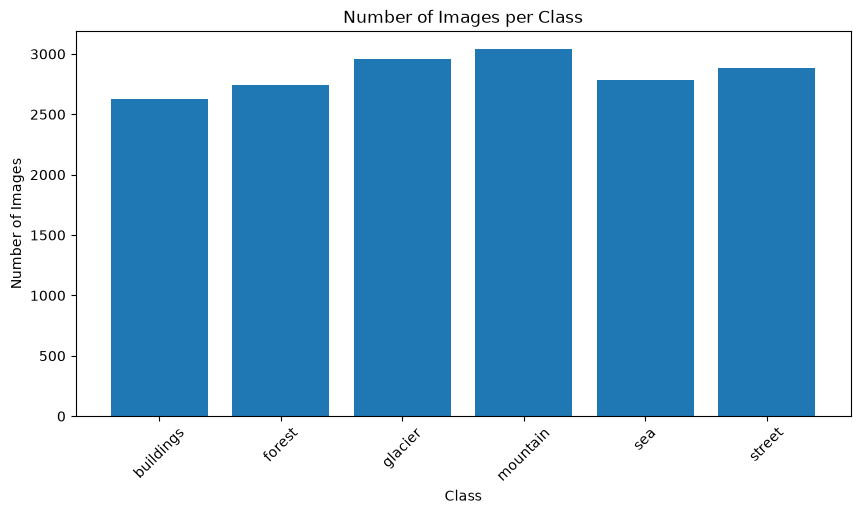

In [4]:
counts = {name: len(images) for name, images in classes.items()}

plt.figure(figsize=(10, 5))
plt.bar(counts.keys(), counts.values())
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

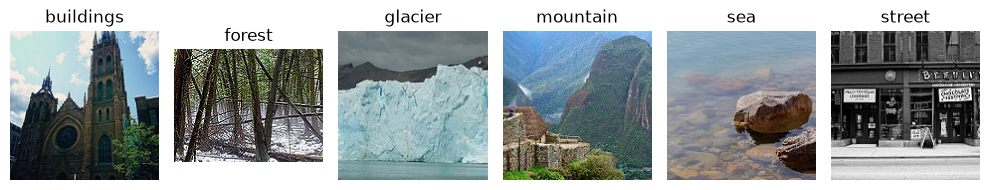

In [5]:
fig, axes = plt.subplots(1, 6, figsize=(10, 18))

for row, (class_name, images) in enumerate(classes.items()):
    img = plt.imread(images[5])

    axes[row].imshow(img)
    axes[row].set_title(class_name)
    axes[row].axis("off")

plt.tight_layout()
plt.show()

In [6]:
from collections import Counter

corrupted = []
dimensions = []

for class_name, images in classes.items():
    for path in images:
        img = cv2.imread(path)

        if img is None:
            corrupted.append(path)
        elif img is not None:
            dimensions.append(img.shape[:2])

print("Unreadable images:", len(corrupted))
print(corrupted[:10])

print("Most common dimensions:")
print(Counter(dimensions).most_common(10))

Unreadable images: 0
[]
Most common dimensions:
[((150, 150), 16979), ((113, 150), 7), ((135, 150), 3), ((111, 150), 3), ((108, 150), 2), ((141, 150), 2), ((136, 150), 2), ((110, 150), 2), ((149, 150), 2), ((143, 150), 2)]


In [7]:
# spliting data to train , validate and test
from sklearn.model_selection import train_test_split
from itertools import chain


labels = [title for title , arr in classes.items() for _ in arr]
test_data = [img for fmt in ('*.jpg', '*.png', '*.jpeg') for img in glob(f'../data/seg_pred/{fmt}')]
img_paths = list(chain.from_iterable(classes.values()))

x_train , x_temp , y_train , y_temp =  train_test_split(img_paths , labels , random_state=100 , test_size=0.2 , stratify=labels)
x_test , x_val , y_test , y_val =   train_test_split(x_temp , y_temp , random_state=100 , test_size=0.5 , stratify=y_temp)

In [8]:
print("Training:", len(x_train))
print("Validation:", len(x_val))
print("Test:", len(x_test))
print("Total:", len(x_train) + len(x_val) + len(x_test))

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts())

print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts())

print("\nTest class distribution:")
print(pd.Series(y_test).value_counts())

Training: 13627
Validation: 1704
Test: 1703
Total: 17034

Training class distribution:
mountain     2430
glacier      2366
street       2306
sea          2227
forest       2196
buildings    2102
Name: count, dtype: int64

Validation class distribution:
mountain     304
glacier      296
street       289
sea          278
forest       274
buildings    263
Name: count, dtype: int64

Test class distribution:
mountain     303
glacier      295
street       288
sea          279
forest       275
buildings    263
Name: count, dtype: int64


In [9]:
import joblib
joblib.dump(
    {
        "classes" : classes ,
        "x_train": x_train,
        "x_val": x_val,
        "x_test": x_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test,
    },
    "../src/data_splits.pkl"
)

['../src/data_splits.pkl']